# Fine-tuning: Grid Search vs Optuna

Este notebook tiene como objetivo analizar las diferencias de rendimiento, eficiencia y convergencia entre la búsqueda de hiperparámetros mediante **Grid Search** y **Optuna**, utilizando los datos obtenidos en los experimentos de finetuning.

In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from siuba import *
import numpy as np

os.chdir(r"B:\12RossyDocumentos\12ProyectoGallinas\11Avance\13_proyecto_gallinas")

# Carga de datos
data_gs = pd.read_csv("artifacts/data_comparativa_modelos_11_1.csv")
data_opt = pd.read_csv("artifacts/results_opt_11.csv")

# Estandarización de columnas para Optuna
data_opt = data_opt.rename(columns={
    'value': 'map50_95',
    'params_MODEL_BATCH': 'batch',
    'params_MODEL_EPOCHS': 'epocas_inicial',
    'params_MODEL_LR': 'learning_rate'
})

print("Datos cargados y estandarizados correctamente.")

Datos cargados y estandarizados correctamente.


## 1. Información

Máximo mAP50-95 Grid Search: 0.2250
Máximo mAP50-95 Optuna: 0.2297


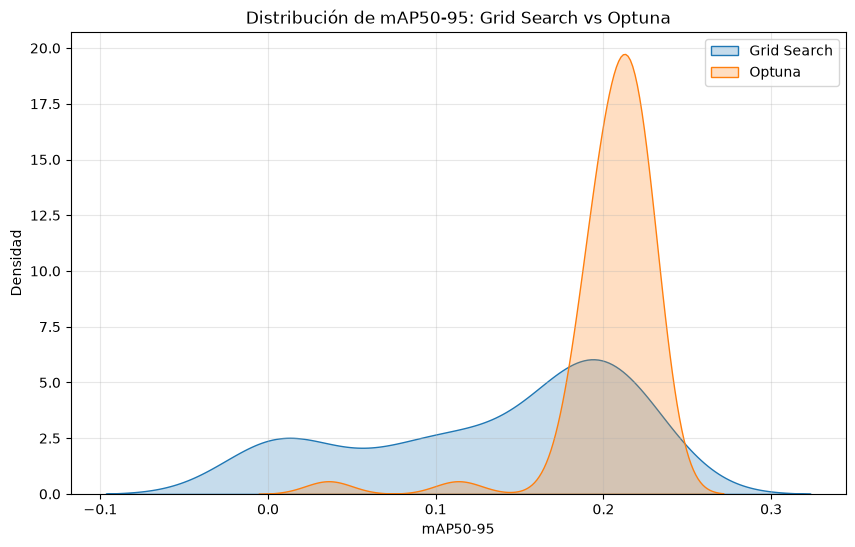

In [3]:
max_gs = data_gs['map50_95'].max()
max_opt = data_opt['map50_95'].max()

print(f"Máximo mAP50-95 Grid Search: {max_gs:.4f}")
print(f"Máximo mAP50-95 Optuna: {max_opt:.4f}")

plt.figure(figsize=(10, 6))
sns.kdeplot(data_gs['map50_95'], label='Grid Search', fill=True)
sns.kdeplot(data_opt['map50_95'], label='Optuna', fill=True)
plt.title("Distribución de mAP50-95: Grid Search vs Optuna")
plt.xlabel("mAP50-95")
plt.ylabel("Densidad")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 2. Convergencia y Línea de Tiempo

Visualizamos cómo evolucionó la métrica `map50_95` a medida que avanzaban los experimentos.

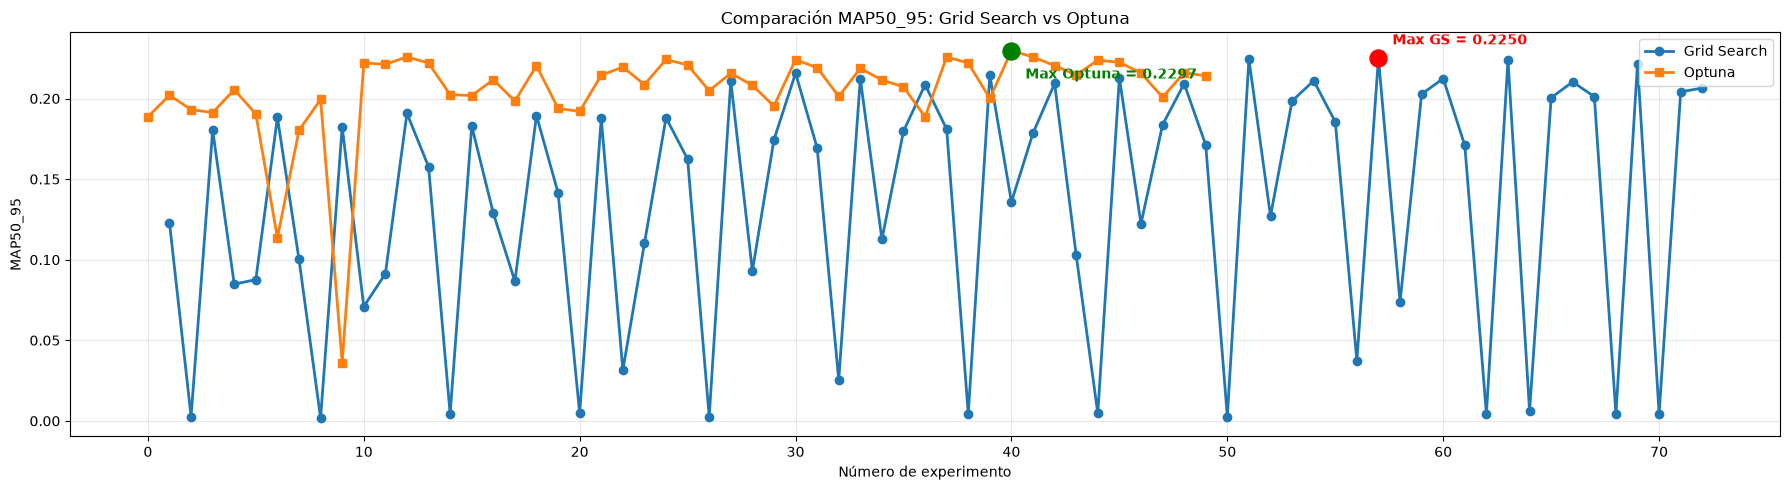

In [4]:
plt.figure(figsize=(18, 5))

# Gráfico de líneas
plt.plot(
    data_gs["numero"],
    data_gs["map50_95"],
    marker="o",
    linewidth=2,
    label="Grid Search",
    color="tab:blue"
)

plt.plot(
    data_opt["number"],
    data_opt["map50_95"],
    marker="s",
    linewidth=2,
    label="Optuna",
    color="tab:orange"
)

# Máximo Grid Search
idx_gs = data_gs["map50_95"].idxmax()
x_gs = data_gs.loc[idx_gs, "numero"]
y_gs = data_gs.loc[idx_gs, "map50_95"]

plt.scatter(x_gs, y_gs, color="red", s=150, zorder=5)
plt.annotate(
    f"Max GS = {y_gs:.4f}",
    (x_gs, y_gs),
    xytext=(10, 10),
    textcoords="offset points",
    color="red",
    fontweight="bold"
)

# Máximo Optuna
idx_opt = data_opt["map50_95"].idxmax()
x_opt = data_opt.loc[idx_opt, "number"]
y_opt = data_opt.loc[idx_opt, "map50_95"]

plt.scatter(x_opt, y_opt, color="green", s=150, zorder=5)
plt.annotate(
    f"Max Optuna = {y_opt:.4f}",
    (x_opt, y_opt),
    xytext=(10, -20),
    textcoords="offset points",
    color="green",
    fontweight="bold"
)

plt.title("Comparación MAP50_95: Grid Search vs Optuna")
plt.xlabel("Número de experimento")
plt.ylabel("MAP50_95")
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

## 3. Eficiencia y Tiempo de Ejecución

Compararemos cuántos experimentos fueron necesarios para alcanzar el mejor resultado y el tiempo total invertido.

In [5]:
# Para Optuna, el tiempo total es la diferencia entre el último y el primero
data_opt['datetime_start'] = pd.to_datetime(data_opt['datetime_start'])
data_opt['datetime_complete'] = pd.to_datetime(data_opt['datetime_complete'])
total_time_opt = (data_opt['datetime_complete'].max() - data_opt['datetime_start'].min()).total_seconds() / 3600

# Para Grid Search, sumamos tiempo_horas
total_time_gs = data_gs['tiempo_horas'].sum()

print(f"Tiempo total Grid Search: {total_time_gs:.2f} horas")
print(f"Tiempo total Optuna: {total_time_opt:.2f} horas")
print(f"Número de experimentos GS: {len(data_gs)}")
print(f"Número de experimentos Optuna: {len(data_opt)}")

Tiempo total Grid Search: 3.21 horas
Tiempo total Optuna: 3.87 horas
Número de experimentos GS: 72
Número de experimentos Optuna: 50


## 4. Análisis Profundo de Hiperparámetros

Analizaremos la influencia de cada parámetro en el resultado final.

--- Mejores Parámetros Grid Search ---
epocas_inicial     150
batch                8
learning_rate     0.01
optimizer          SGD
Name: 56, dtype: object

--- Mejores Parámetros Optuna ---
epocas_inicial         185
batch                    8
learning_rate     0.006637
Name: 40, dtype: object


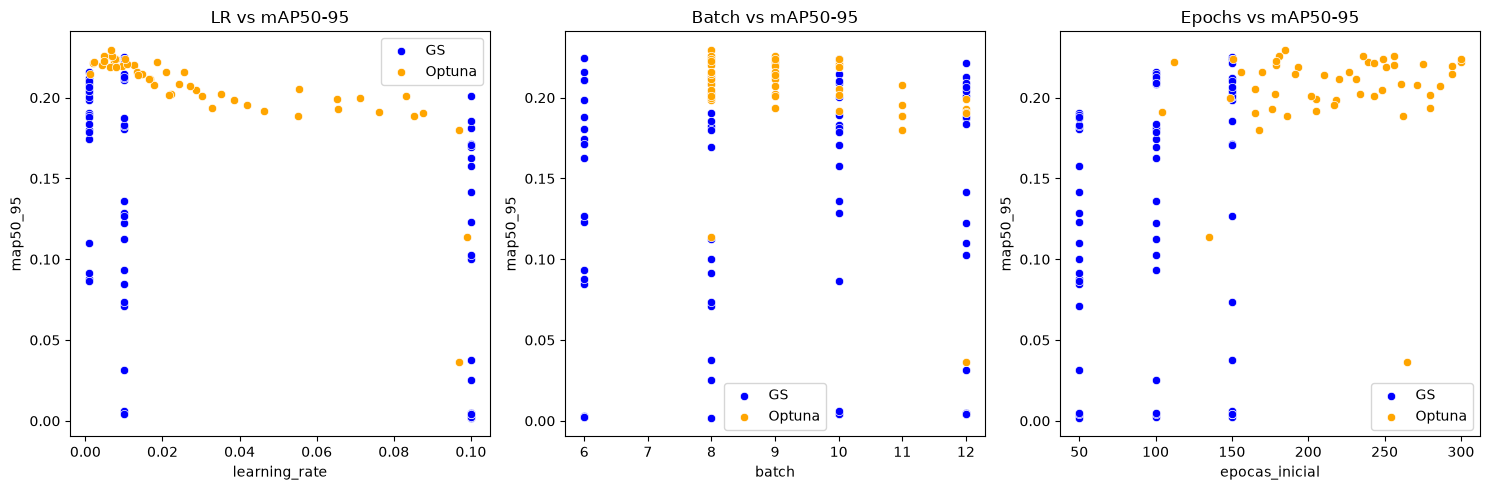

In [6]:
# a. Comparativa de Mejores Parámetros
best_gs = data_gs.loc[data_gs['map50_95'].idxmax()]
best_opt = data_opt.loc[data_opt['map50_95'].idxmax()]

print("--- Mejores Parámetros Grid Search ---")
print(best_gs[['epocas_inicial', 'batch', 'learning_rate', 'optimizer']])

print("\n--- Mejores Parámetros Optuna ---")
print(best_opt[['epocas_inicial', 'batch', 'learning_rate']])

# b. Análisis de Correlación
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
sns.scatterplot(data=data_gs, x='learning_rate', y='map50_95', color='blue', label='GS')
sns.scatterplot(data=data_opt, x='learning_rate', y='map50_95', color='orange', label='Optuna')
plt.title("LR vs mAP50-95")
plt.legend()

plt.subplot(1, 3, 2)
sns.scatterplot(data=data_gs, x='batch', y='map50_95', color='blue', label='GS')
sns.scatterplot(data=data_opt, x='batch', y='map50_95', color='orange', label='Optuna')
plt.title("Batch vs mAP50-95")
plt.legend()

plt.subplot(1, 3, 3)
sns.scatterplot(data=data_gs, x='epocas_inicial', y='map50_95', color='blue', label='GS')
sns.scatterplot(data=data_opt, x='epocas_inicial', y='map50_95', color='orange', label='Optuna')
plt.title("Epochs vs mAP50-95")
plt.legend()

plt.tight_layout()
plt.show()

## 5. Análisis de Estabilidad (Boxplots)

Evaluamos la variabilidad de los resultados para ver cuál método es más robusto.

C:\Users\Rossy Cañari\AppData\Local\Temp\ipykernel_4124\2369925981.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='metodo', y='map50_95', data=combined_df, palette="Set2")


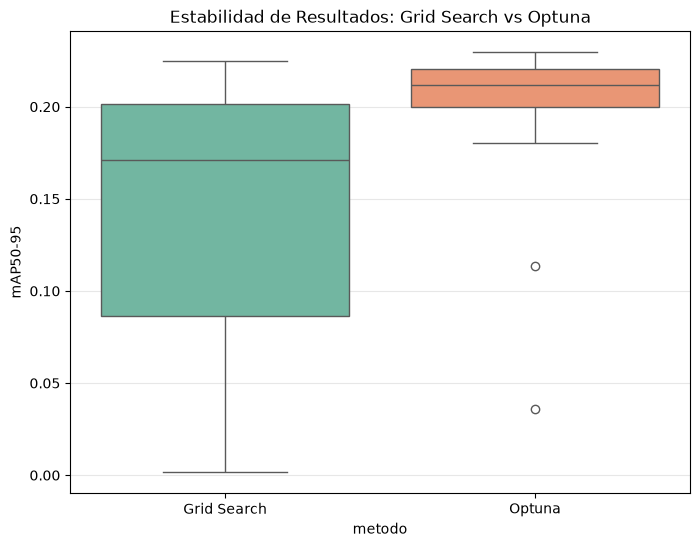

In [7]:
combined_df = pd.concat([
    data_gs[['map50_95']].assign(metodo='Grid Search'),
    data_opt[['map50_95']].assign(metodo='Optuna')
])

plt.figure(figsize=(8, 6))
sns.boxplot(x='metodo', y='map50_95', data=combined_df, palette="Set2")
plt.title("Estabilidad de Resultados: Grid Search vs Optuna")
plt.ylabel("mAP50-95")
plt.grid(True, axis='y', alpha=0.3)
plt.show()